# Cinemática — teoría e interpretación física
### Física · 1.º de Bachillerato

**Objetivo.** Comprender cómo se describe el movimiento y qué significan físicamente las operaciones matemáticas que utilizamos.

Este cuaderno combina teoría, ejemplos independientes e ilustraciones ejecutables. Ejecuta las celdas en orden. Las figuras utilizan únicamente `numpy` y `matplotlib`.

**Convenciones:** tiempo en segundos (s), posición en metros (m), velocidad en m/s y aceleración en m/s². Los vectores se representan mediante flechas o negrita.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True, "font.size": 11})

## 1. Posición, trayectoria, desplazamiento y distancia

La **posición** indica dónde está un móvil respecto a un origen. En tres dimensiones:

$$\vec r(t)=x(t)\vec i+y(t)\vec j+z(t)\vec k$$

Los vectores $\vec i$, $\vec j$ y $\vec k$ son vectores unitarios que apuntan en las direcciones de los ejes X, Y y Z. En el plano basta con X e Y.

La **trayectoria** es la curva formada por las posiciones sucesivas. El **desplazamiento** es el vector que une la posición inicial y final:

$$\Delta\vec r=\vec r(t_f)-\vec r(t_i)$$

La **distancia recorrida** mide la longitud total del camino y es un escalar. No coincide necesariamente con el módulo del desplazamiento.

**Ejemplo:** una persona recorre una vuelta completa de 400 m en una pista y termina donde empezó. La distancia es 400 m, pero el desplazamiento es cero.

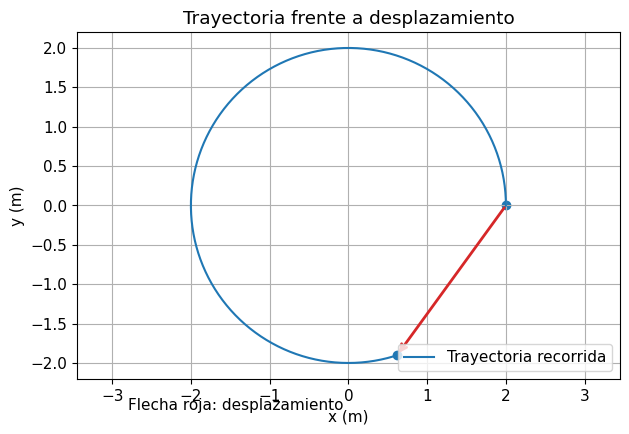

In [ ]:
theta = np.linspace(0, 1.6*np.pi, 240)
x,y = 2*np.cos(theta),2*np.sin(theta)
fig,ax=plt.subplots()
ax.plot(x,y,label="Trayectoria recorrida")
ax.scatter([x[0],x[-1]],[y[0],y[-1]])
ax.annotate("",xy=(x[-1],y[-1]),xytext=(x[0],y[0]),arrowprops=dict(arrowstyle="->",lw=2,color="tab:red"))
ax.text(-2.8,-2.6,"Flecha roja: desplazamiento")
ax.set(xlabel="x (m)",ylabel="y (m)",title="Trayectoria frente a desplazamiento")
ax.axis("equal");ax.legend();plt.show()

### De ecuaciones paramétricas a la trayectoria

Las funciones $x(t)$ e $y(t)$ dicen dónde está el móvil **en cada instante**. Si eliminamos $t$, obtenemos una relación $y(x)$ que describe la **forma geométrica** de la trayectoria, pero pierde información sobre cuándo pasa por cada punto.

Por ejemplo, $x(t)=2t$ e $y(t)=t^2$ implican $t=x/2$ y, por tanto:

$$y=\frac{x^2}{4}$$

Es una parábola. La forma de la curva no determina por sí sola la rapidez ni el sentido de movimiento.

## 2. Velocidad: variación de la posición

La **velocidad media** entre dos instantes es:

$$\vec v_m=\frac{\Delta\vec r}{\Delta t}$$

La **velocidad instantánea** es el límite cuando el intervalo de tiempo tiende a cero, es decir, la derivada:

$$\boxed{\vec v(t)=\frac{d\vec r}{dt}}$$

**Interpretación de la derivada:** expresa cuánto cambia la posición por cada segundo en un instante. Geométricamente, la velocidad es tangente a la trayectoria siempre que sea distinta de cero.

En coordenadas cartesianas se deriva cada componente por separado:

$$\vec v=\frac{dx}{dt}\vec i+\frac{dy}{dt}\vec j+\frac{dz}{dt}\vec k$$

La **celeridad** es el módulo de la velocidad, siempre no negativo:

$$\boxed{v=|\vec v|=\sqrt{v_x^2+v_y^2+v_z^2}}$$

**Velocidad y celeridad no son lo mismo:** una indica también dirección y sentido; la otra solo rapidez. La **rapidez media** es distancia total dividida por tiempo total y no debe confundirse con el módulo de la velocidad media.

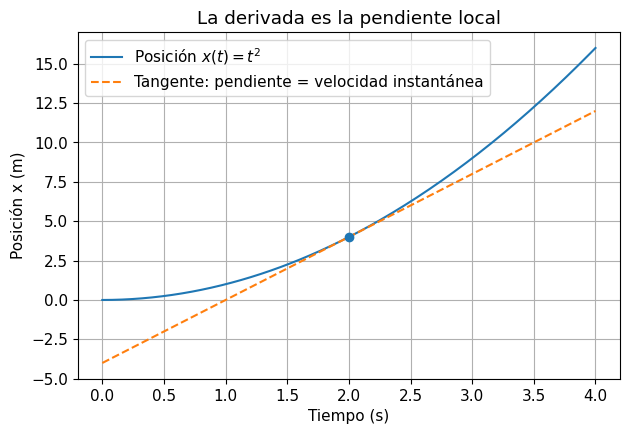

In [ ]:
t=np.linspace(0,4,200)
x=t**2
t0=2
fig,ax=plt.subplots()
ax.plot(t,x,label=r"Posición $x(t)=t^2$")
ax.plot(t,t0**2+2*t0*(t-t0),"--",label="Tangente: pendiente = velocidad instantánea")
ax.scatter([t0],[t0**2],zorder=4)
ax.set(xlabel="Tiempo (s)",ylabel="Posición x (m)",title="La derivada es la pendiente local")
ax.legend();plt.show()

## 3. Aceleración: variación de la velocidad

La aceleración instantánea es:

$$\boxed{\vec a(t)=\frac{d\vec v}{dt}=\frac{d^2\vec r}{dt^2}}$$

Sus unidades son m/s²: una aceleración de 2 m/s² en X significa que la componente horizontal de la velocidad aumenta 2 m/s cada segundo.

**Cuidado con el signo:** una aceleración negativa en X no significa necesariamente frenar. Si el móvil se desplaza en sentido negativo de X y su aceleración también apunta en ese sentido, su celeridad aumenta.

**Ejemplo unidimensional:**

$$x(t)=3+4t-t^2,\qquad v_x(t)=4-2t,\qquad a_x(t)=-2$$

El móvil primero avanza en X, se detiene instantáneamente en $t=2$ s y después invierte el sentido. Su aceleración es constante durante todo el proceso.

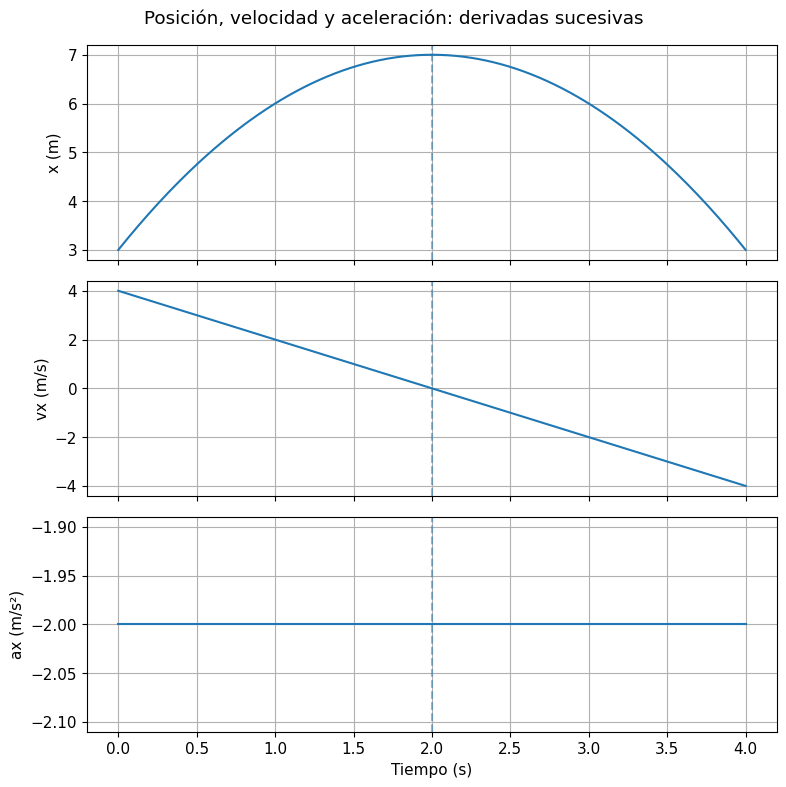

In [ ]:
t=np.linspace(0,4,250)
fig,axs=plt.subplots(3,1,figsize=(8,8),sharex=True)
for ax,values,label in zip(axs,[3+4*t-t*t,4-2*t,-2*np.ones_like(t)],["x (m)","vx (m/s)","ax (m/s²)"]):
    ax.plot(t,values);ax.set_ylabel(label);ax.axvline(2,ls="--",alpha=.5)
axs[-1].set_xlabel("Tiempo (s)")
fig.suptitle("Posición, velocidad y aceleración: derivadas sucesivas")
fig.tight_layout();plt.show()

## 4. Componentes cartesianas e intrínsecas

Las **componentes cartesianas** describen la aceleración según ejes fijos:

$$\vec a=a_x\vec i+a_y\vec j+a_z\vec k$$

Las **componentes intrínsecas** la describen respecto al movimiento mismo:

$$\boxed{\vec a=a_t\hat t+a_n\hat n}$$

- **Tangencial ($a_t$):** modifica la *celeridad*; es positiva cuando aumenta y negativa cuando disminuye.
- **Normal ($a_n$):** modifica la *dirección* de la velocidad; apunta hacia el centro de curvatura y su magnitud es no negativa.

Cuando $v>0$:

$$\boxed{a_t=\frac{dv}{dt}=\frac{\vec v\cdot\vec a}{|\vec v|}}$$

El **producto escalar** $\vec v\cdot\vec a=v_xa_x+v_ya_y+v_za_z$ mide cuánto de la aceleración está alineado con la velocidad.

Como las componentes tangencial y normal son perpendiculares:

$$\boxed{a_n=\sqrt{|\vec a|^2-a_t^2}}$$

En un instante de reposo ($v=0$), la dirección tangente definida por la velocidad no está determinada y las fórmulas con división por $v$ no pueden aplicarse directamente.

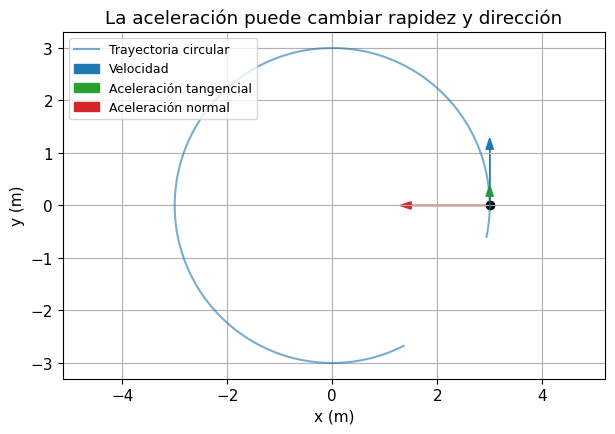

In [ ]:
R=3.0; speed=4.0; at=1.2
an=speed**2/R
fig,ax=plt.subplots()
phi=np.linspace(-.2,1.65*np.pi,350)
ax.plot(R*np.cos(phi),R*np.sin(phi),alpha=.6,label="Trayectoria circular")
p=np.array([R,0.]); tangent=np.array([0.,1.]); normal=np.array([-1.,0.])
scale=.32
for vec,label,color in [(tangent*speed,"Velocidad", "tab:blue"),(tangent*at,"Aceleración tangencial","tab:green"),(normal*an,"Aceleración normal","tab:red")]:
    ax.arrow(*p,*(scale*vec),head_width=.14,length_includes_head=True,color=color,label=label)
ax.scatter(*p,color="black");ax.set(xlabel="x (m)",ylabel="y (m)",title="La aceleración puede cambiar rapidez y dirección")
ax.axis("equal");ax.legend(loc="upper left",fontsize=9);plt.show()

## 5. Curvatura y radio de curvatura

En cada punto de una trayectoria curva podemos imaginar una circunferencia que se ajusta localmente a la curva. Su radio es el **radio de curvatura** $R$.

$$\boxed{a_n=\frac{v^2}{R}}\qquad\Longrightarrow\qquad\boxed{R=\frac{v^2}{a_n}}$$

**Sentido físico:** una curva más cerrada tiene radio menor y exige mayor aceleración normal a igual celeridad. Si duplicamos la celeridad manteniendo el radio, la aceleración normal se multiplica por cuatro.

En una trayectoria recta, la curvatura es cero y se expresa $R\to\infty$; por tanto $a_n=0$. Si $a_n=0$ en un solo instante, esto solo informa de la curvatura local en ese instante, no de toda la trayectoria.

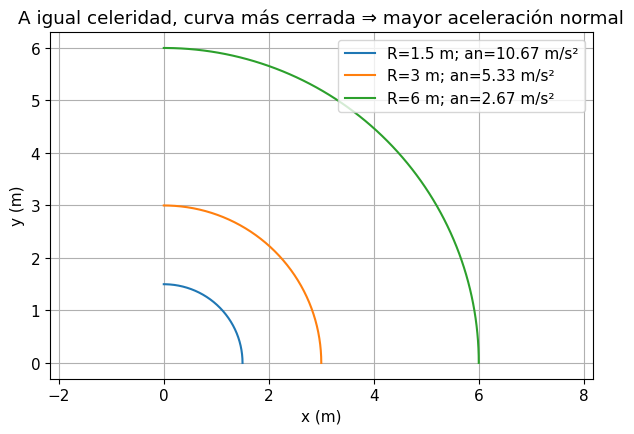

In [ ]:
radii=[1.5,3.,6.];speed=4.
fig,ax=plt.subplots()
for R in radii:
    phi=np.linspace(0,np.pi/2,200)
    ax.plot(R*np.cos(phi),R*np.sin(phi),label=f"R={R:g} m; an={speed**2/R:.2f} m/s²")
ax.set(xlabel="x (m)",ylabel="y (m)",title="A igual celeridad, curva más cerrada ⇒ mayor aceleración normal")
ax.axis("equal");ax.legend();plt.show()

## 6. Movimiento rectilíneo, curvilíneo y circular

**Por la trayectoria:**

- **Rectilíneo:** el movimiento sigue una recta. Si $v>0$, su aceleración normal es cero.
- **Curvilíneo:** la dirección del movimiento cambia a lo largo de una curva.
- **Circular:** la trayectoria es una circunferencia de radio fijo.

**Por la celeridad:**

- **Uniforme:** $v$ constante, por tanto $a_t=0$.
- **No uniforme:** cambia la celeridad, de modo que $a_t$ no es siempre cero.

**Por la aceleración:** un movimiento rectilíneo con aceleración cartesiana constante es un **MRUA** (también llamado MRUV); un movimiento rectilíneo con velocidad constante es un **MRU**.

### Movimiento circular uniforme (MCU)

Una parametrización de una circunferencia es:

$$x(t)=R\cos(\omega t),\qquad y(t)=R\sin(\omega t)$$

Aquí $R$ es el radio y $\omega$ la velocidad angular (rad/s). Al elevar al cuadrado y sumar:

$$x^2+y^2=R^2$$

Al derivar las coordenadas se obtiene una velocidad tangente a la circunferencia de módulo constante:

$$\boxed{v=R|\omega|}$$

La aceleración es radial hacia el centro:

$$\boxed{a_t=0,\qquad a_n=\frac{v^2}{R}=R\omega^2}$$

**Idea clave:** celeridad constante no implica aceleración nula: en el MCU cambia continuamente la dirección de la velocidad.

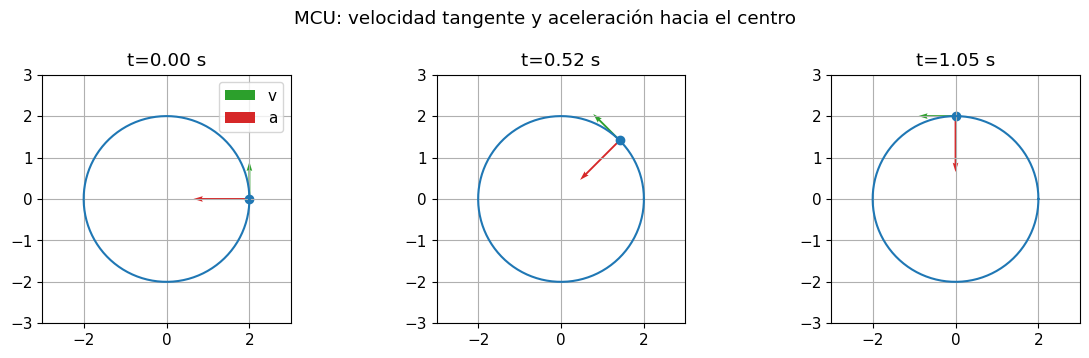

In [ ]:
R=2.;omega=1.5
fig,axs=plt.subplots(1,3,figsize=(12,3.6))
for ax,tm in zip(axs,[0,np.pi/(4*omega),np.pi/(2*omega)]):
    ph=np.linspace(0,2*np.pi,300);ax.plot(R*np.cos(ph),R*np.sin(ph))
    p=np.array([R*np.cos(omega*tm),R*np.sin(omega*tm)])
    v=R*omega*np.array([-np.sin(omega*tm),np.cos(omega*tm)])
    a=-omega**2*p
    ax.quiver(*p,*(v*.3),angles="xy",scale_units="xy",scale=1,color="tab:green",label="v")
    ax.quiver(*p,*(a*.3),angles="xy",scale_units="xy",scale=1,color="tab:red",label="a")
    ax.scatter(*p);ax.set(title=f"t={tm:.2f} s",xlim=(-3,3),ylim=(-3,3));ax.set_aspect("equal");ax.grid(True)
axs[0].legend();fig.suptitle("MCU: velocidad tangente y aceleración hacia el centro");fig.tight_layout();plt.show()

## 7. Cómo interpretar y resolver un problema

1. **Identifica qué magnitud se conoce:** posición, velocidad, celeridad o aceleración; distingue vectores de escalares.
2. **Fija los ejes y las unidades.** Un signo negativo solo tiene sentido respecto al eje elegido.
3. **Deriva cuando buscas tasas instantáneas de cambio:** de posición a velocidad; de velocidad a aceleración.
4. **Calcula módulos** solo cuando se pide una magnitud escalar como celeridad o módulo de aceleración.
5. **Elimina el tiempo** cuando se pide la forma geométrica de la trayectoria.
6. **Separa cambio de rapidez y cambio de dirección** mediante $a_t$ y $a_n$, si $v>0$.
7. **Clasifica el movimiento con argumentos físicos**, no únicamente por el aspecto de una fórmula.
8. **Comprueba unidades y casos límite:** si $a_n=0$ y $v>0$, la trayectoria es localmente recta; si $a_t=0$, la celeridad no cambia en ese instante.

### Errores habituales

- Confundir desplazamiento con distancia recorrida.
- Confundir velocidad vectorial con celeridad.
- Suponer que aceleración negativa equivale a frenar.
- Pensar que movimiento uniforme significa aceleración total cero.
- Concluir que una trayectoria es recta solo porque una componente de la aceleración es cero.
- Usar $a_t=(\vec v\cdot\vec a)/v$ en instantes con $v=0$.

## 8. Resumen de fórmulas

| Magnitud | Expresión | Interpretación |
|---|---|---|
| Posición | $\vec r=x\vec i+y\vec j+z\vec k$ | Dónde está |
| Desplazamiento | $\Delta\vec r=\vec r_f-\vec r_i$ | Cambio neto de posición |
| Velocidad media | $\vec v_m=\Delta\vec r/\Delta t$ | Desplazamiento por tiempo |
| Velocidad instantánea | $\vec v=d\vec r/dt$ | Cambio instantáneo de posición |
| Celeridad | $v=|\vec v|$ | Rapidez sin dirección |
| Aceleración | $\vec a=d\vec v/dt$ | Cambio instantáneo de velocidad |
| Tangencial | $a_t=dv/dt$ | Cambio de rapidez |
| Normal | $a_n=\sqrt{a^2-a_t^2}$ | Cambio de dirección |
| Radio de curvatura | $R=v^2/a_n$ | Apertura local de la curva |
| MCU | $v=R|\omega|$ | Rapidez en circunferencia |

**Regla conceptual final:** posición, velocidad y aceleración responden a preguntas distintas. Las derivadas conectan esas preguntas, pero el significado físico de cada vector es lo que permite interpretar correctamente el movimiento.